In [9]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("PredictOps AI - Environment Ready!")

PredictOps AI - Environment Ready!


# 1. Dataset Loading

We are using the NASA C-MAPSS FD001 dataset
to predict the Remaining Useful Life (RUL)
of turbofan engines.

In [11]:
import pandas as pd
import numpy as np

columns = (
    ['unit_number', 'time_cycles']
    + [f'setting_{i}' for i in range(1, 4)]
    + [f's_{i}' for i in range(1, 22)]
)

train = pd.read_csv(
    '../data/raw/train_FD001.txt',
    sep=r'\s+',
    header=None
)

train.columns = columns

print("Dataset loaded successfully!")
print("Shape:", train.shape)

display(train.head())

Dataset loaded successfully!
Shape: (20631, 26)


,unit_number,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [ ]:

test = pd.read_csv(
    '../data/raw/test_FD001.txt',
    sep=r'\s+',
    header=None
)

test.columns = columns


y_test = pd.read_csv(
    '../data/raw/RUL_FD001.txt',
    sep=r'\s+',
    header=None,
    names=['RUL']
)

print("Training data:", train.shape)
print("Testing data:", test.shape)
print("Actual RUL:", y_test.shape)

Training data: (20631, 26)
Testing data: (13096, 26)
Actual RUL: (100, 1)


## 2. Data Inspection

We inspect the dataset to understand its structure, data types,
missing values, duplicate records and statistical properties.

In [13]:
print("Training Dataset Information")
train.info()

Training Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   unit_number  20631 non-null  int64  
 1   time_cycles  20631 non-null  int64  
 2   setting_1    20631 non-null  float64
 3   setting_2    20631 non-null  float64
 4   setting_3    20631 non-null  float64
 5   s_1          20631 non-null  float64
 6   s_2          20631 non-null  float64
 7   s_3          20631 non-null  float64
 8   s_4          20631 non-null  float64
 9   s_5          20631 non-null  float64
 10  s_6          20631 non-null  float64
 11  s_7          20631 non-null  float64
 12  s_8          20631 non-null  float64
 13  s_9          20631 non-null  float64
 14  s_10         20631 non-null  float64
 15  s_11         20631 non-null  float64
 16  s_12         20631 non-null  float64
 17  s_13         20631 non-null  float64
 18  s_14         20631 non-null 

In [14]:
print(train.isnull().sum().sum())

0


In [15]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 0


In [16]:
display(train.describe().T)

,count,mean,std,min,25%,50%,75%,max
unit_number,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
time_cycles,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
s_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200


In [17]:
constant_cols = train.columns[train.nunique() == 1]

print("Constant columns:")
print(constant_cols.tolist())

print("\nNumber of constant columns:", len(constant_cols))

Constant columns:
['setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19']

Number of constant columns: 7


In [18]:
# Identify constant columns
constant_cols = train.columns[train.nunique() == 1]

# Remove constant columns
train.drop(columns=constant_cols, inplace=True)
test.drop(columns=constant_cols, inplace=True)

print("Removed columns:", constant_cols.tolist())

print("New training shape:", train.shape)
print("New testing shape:", test.shape)

Removed columns: ['setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19']
New training shape: (20631, 19)
New testing shape: (13096, 19)


C:\Users\Niraj Sah\AppData\Local\Temp\ipykernel_5124\1986910386.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train.drop(columns=constant_cols, inplace=True)
C:\Users\Niraj Sah\AppData\Local\Temp\ipykernel_5124\1986910386.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test.drop(columns=constant_cols, inplace=True)


## 3. Engine Lifetime Analysis

Analyze the maximum operating cycles of each engine
to understand the distribution of engine lifetimes.

In [20]:
engine_lifetime = train.groupby('unit_number')['time_cycles'].max()

print(engine_lifetime.head(10))

unit_number
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: time_cycles, dtype: int64


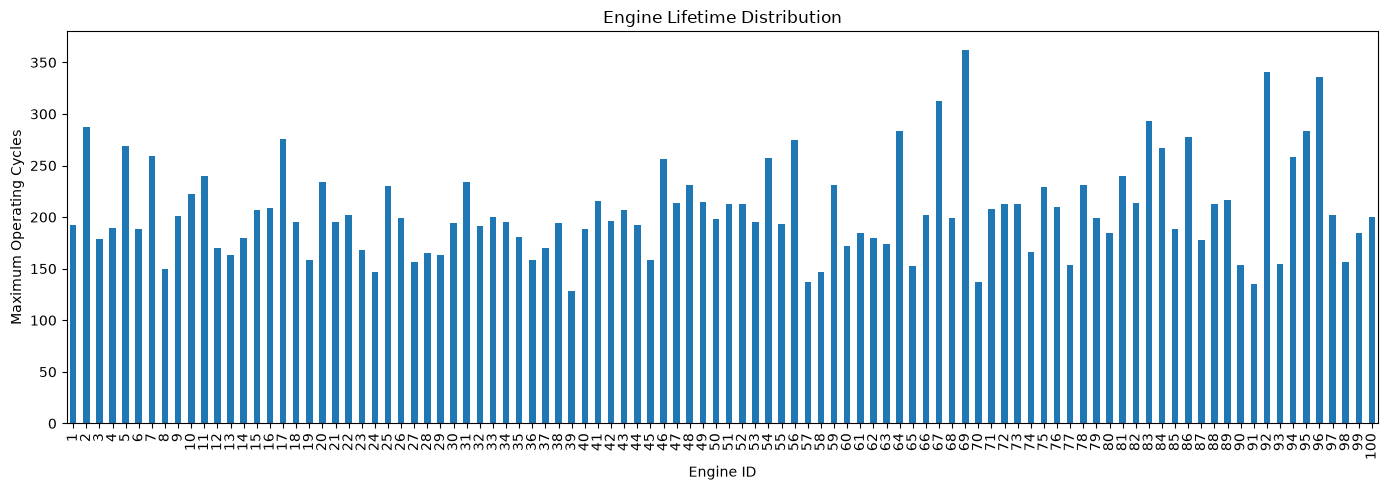

In [21]:
plt.figure(figsize=(14, 5))

engine_lifetime.plot(kind='bar')

plt.title("Engine Lifetime Distribution")
plt.xlabel("Engine ID")
plt.ylabel("Maximum Operating Cycles")

plt.tight_layout()
plt.show()

## 4. Remaining Useful Life (RUL) Calculation

RUL represents the number of operating cycles remaining
before an engine reaches its simulated failure point.

We generate RUL labels for supervised machine learning.

In [22]:
# Calculate maximum cycle for each engine

max_cycles = train.groupby('unit_number')['time_cycles'].max()

# Generate RUL labels

train['RUL'] = train.apply(
    lambda row: max_cycles[row['unit_number']] - row['time_cycles'],
    axis=1
)

display(train[['unit_number', 'time_cycles', 'RUL']].head(10))

,unit_number,time_cycles,RUL
0,1,1,191.0
1,1,2,190.0
2,1,3,189.0
3,1,4,188.0
4,1,5,187.0
5,1,6,186.0
6,1,7,185.0
7,1,8,184.0
8,1,9,183.0
9,1,10,182.0


In [23]:
train['RUL'] = train['RUL'].clip(upper=125)

print(train[['unit_number', 'time_cycles', 'RUL']].head(10))

   unit_number  time_cycles    RUL
0            1            1  125.0
1            1            2  125.0
2            1            3  125.0
3            1            4  125.0
4            1            5  125.0
5            1            6  125.0
6            1            7  125.0
7            1            8  125.0
8            1            9  125.0
9            1           10  125.0


## 5. RUL Distribution Analysis

Analyze the distribution of Remaining Useful Life values
across all engine observations.

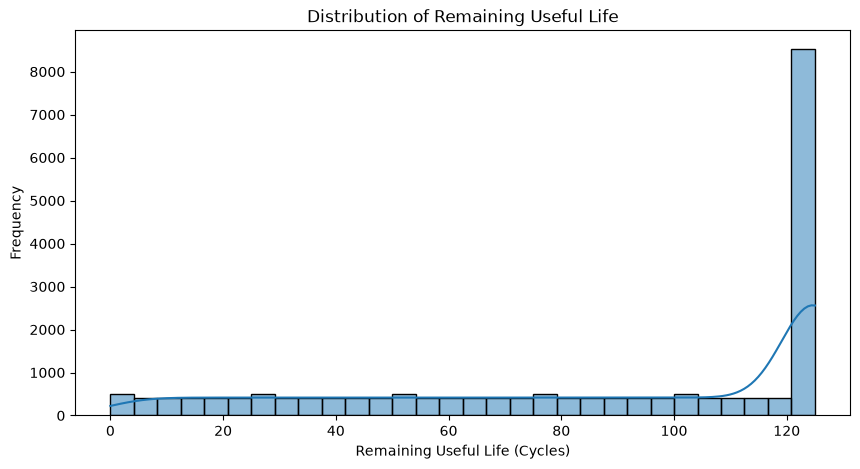

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train['RUL'],
    bins=30,
    kde=True
)

plt.title("Distribution of Remaining Useful Life")
plt.xlabel("Remaining Useful Life (Cycles)")
plt.ylabel("Frequency")

plt.show()

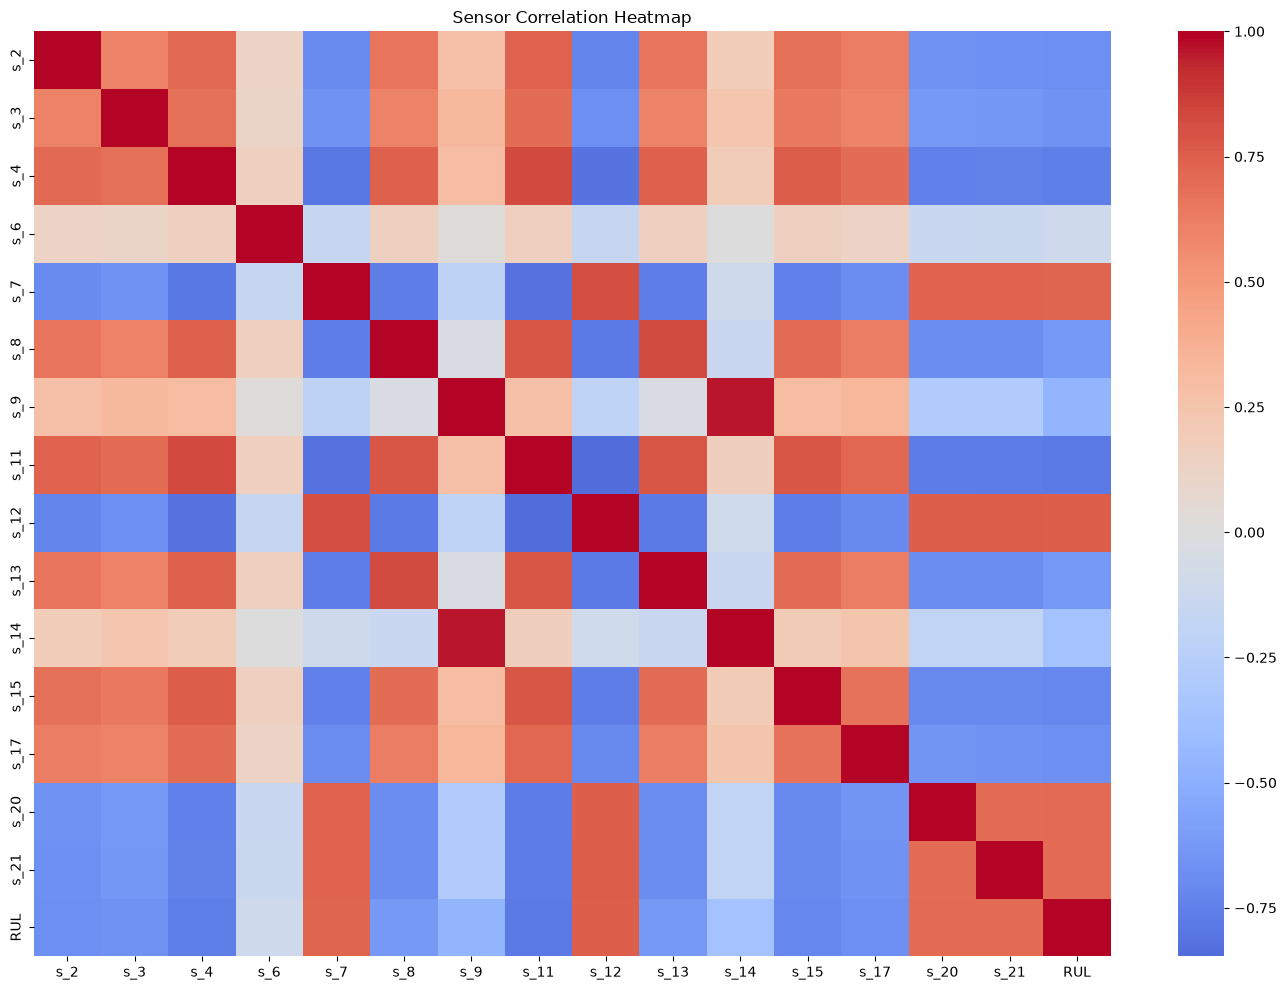

In [25]:


sensor_cols = [col for col in train.columns if col.startswith('s_')]

corr = train[sensor_cols + ['RUL']].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title("Sensor Correlation Heatmap")
plt.tight_layout()
plt.show()

In [26]:
# Correlation of each sensor with RUL

rul_corr = corr['RUL'].drop('RUL')

# Sort by absolute correlation
rul_corr = rul_corr.reindex(
    rul_corr.abs().sort_values(ascending=False).index
)

print(rul_corr)

s_11   -0.775230
s_4    -0.757157
s_12    0.748870
s_7     0.733021
s_15   -0.720858
s_21    0.707334
s_20    0.704626
s_17   -0.680829
s_2    -0.678458
s_3    -0.655030
s_8    -0.624568
s_13   -0.624034
s_9    -0.462151
s_14   -0.369753
s_6    -0.108289
Name: RUL, dtype: float64


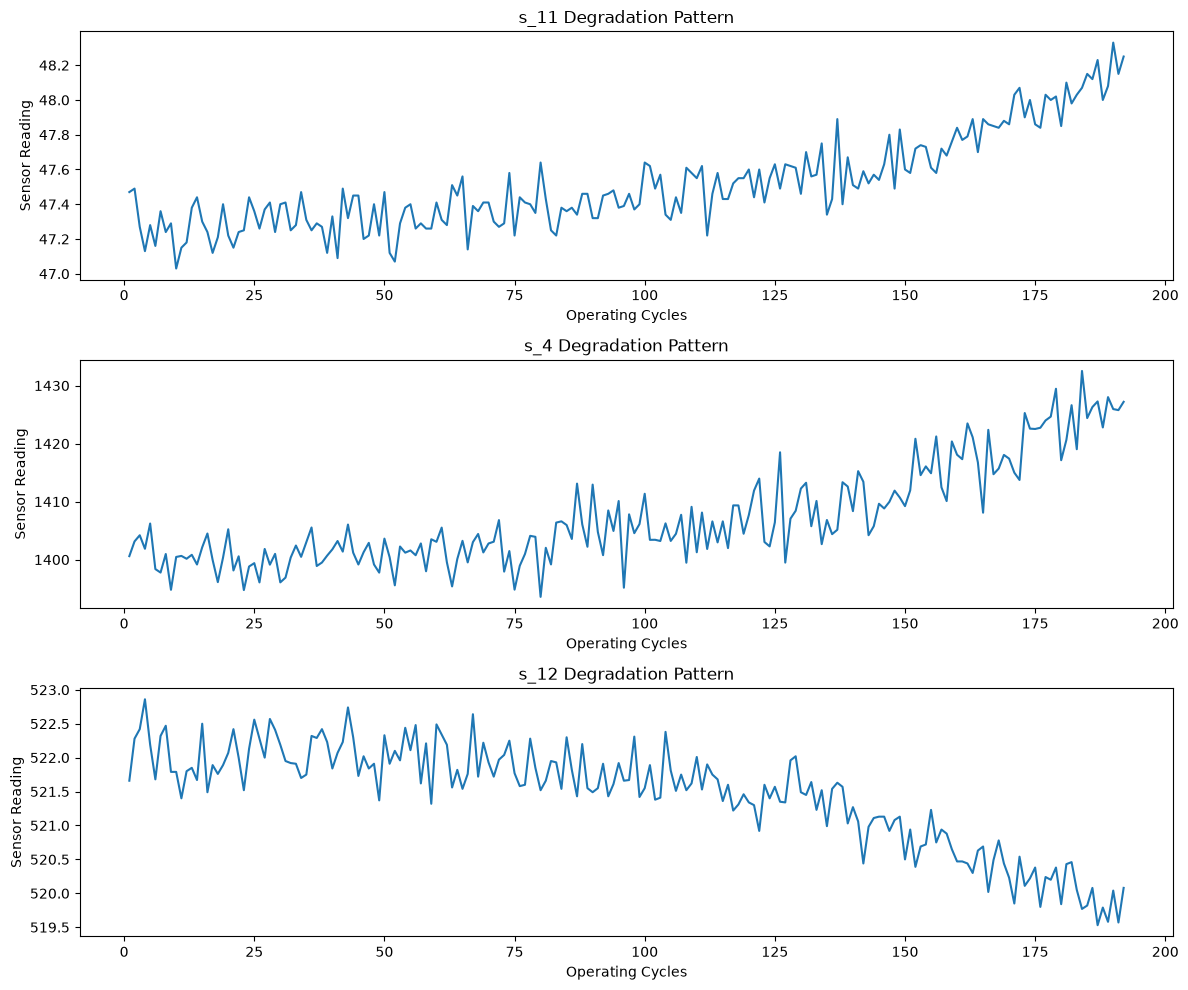

In [27]:
# Select engine 1
engine_data = train[train['unit_number'] == 1]

# Select the three most correlated sensors
selected_sensors = ['s_11', 's_4', 's_12']

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for i, sensor in enumerate(selected_sensors):

    axes[i].plot(
        engine_data['time_cycles'],
        engine_data[sensor]
    )

    axes[i].set_title(f'{sensor} Degradation Pattern')
    axes[i].set_xlabel('Operating Cycles')
    axes[i].set_ylabel('Sensor Reading')

plt.tight_layout()
plt.show()

In [28]:
selected_sensors = [
    's_11', 's_4', 's_12', 's_7',
    's_15', 's_21', 's_20', 's_17'
]

def create_features(df):

    df = df.copy()

    df = df.sort_values(
        ['unit_number', 'time_cycles']
    )

    for sensor in selected_sensors:

        # Rolling mean of last 5 cycles
        df[f'{sensor}_mean_5'] = (
            df.groupby('unit_number')[sensor]
            .transform(lambda x: x.rolling(5, min_periods=1).mean())
        )

        # Rolling standard deviation
        df[f'{sensor}_std_5'] = (
            df.groupby('unit_number')[sensor]
            .transform(lambda x: x.rolling(5, min_periods=1).std())
            .fillna(0)
        )

        # Change compared to 5 cycles earlier
        df[f'{sensor}_trend_5'] = (
            df.groupby('unit_number')[sensor]
            .diff(5)
            .fillna(0)
        )

    return df

In [29]:
train_fe = create_features(train)
test_fe = create_features(test)

print("Original features:", train.shape[1])
print("Engineered features:", train_fe.shape[1])

display(train_fe.head())

Original features: 20
Engineered features: 44


,unit_number,time_cycles,setting_1,setting_2,s_2,s_3,s_4,s_6,s_7,s_8,...,s_15_trend_5,s_21_mean_5,s_21_std_5,s_21_trend_5,s_20_mean_5,s_20_std_5,s_20_trend_5,s_17_mean_5,s_17_std_5,s_17_trend_5
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,...,0.0,23.419000,0.000000,0.0,39.060000,0.000000,0.0,392.000000,0.000000,0.0
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,...,0.0,23.421300,0.003253,0.0,39.030000,0.042426,0.0,392.000000,0.000000,0.0
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,...,0.0,23.395600,0.044573,0.0,39.003333,0.055076,0.0,391.333333,1.154701,0.0
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,...,0.0,23.390175,0.037977,0.0,38.972500,0.076322,0.0,391.500000,1.000000,0.0
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,...,0.0,23.393020,0.033498,0.0,38.958000,0.073621,0.0,391.800000,1.095445,0.0


In [30]:
from sklearn.model_selection import GroupShuffleSplit

# Separate input features and target
X = train_fe.drop(columns=['unit_number', 'RUL'])
y = train_fe['RUL']

# Split based on engine IDs
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train_fe['unit_number'])
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("Training engines:",
      train_fe.iloc[train_idx]['unit_number'].nunique())

print("Validation engines:",
      train_fe.iloc[val_idx]['unit_number'].nunique())

Training shape: (16561, 42)
Validation shape: (4070, 42)
Training engines: 80
Validation engines: 20


In [31]:
%pip install xgboost lightgbm

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 10.1 MB/s eta 0:00:05
   -- ------------------------------------- 3.1/48.9 MB 10.3 MB/s eta 0:00:05
   ---- ----------------------------------- 5.5/48.9 MB 11.1 MB/s eta 0:00:04
   ------ --------------------------------- 7.9/48.9 MB 10.6 MB/s eta 0:00:04
   ------- -------------------------------- 9.4/48.9 MB 9.9 MB/s eta 0:00:05
   --------- ------------------------------ 11.8/48.9 MB 10.1 MB/s eta 0:00:04
   ----------- ---------------------------- 14.2/48.9 MB 10.3 MB/s eta 0:00:04
   ------------- -------------------------- 16.3/48.9 MB 10.4 MB/s eta 0:00:04
   --------------- ------------------------ 18.9/48.9 MB 10.5 MB/s eta 0:00:03
   ----------------- ---------------------- 21.5/48.9 MB 10.7 MB/s eta 0:00:03
   ------------------- -------------------- 23.9/48.9 MB 10.7 MB/s eta 0:00:03
   --------------------- ------------------ 26.0/48.9 MB 10.7 MB/s 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

import time

In [33]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=400,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

results = []

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    start = time.time()

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    elapsed = time.time() - start

    trained_models[name] = model

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'Training Time': round(elapsed, 2)
    })

    print(f"{name} completed!")

Training Random Forest...
Random Forest completed!
Training XGBoost...
XGBoost completed!
Training LightGBM...
LightGBM completed!


In [34]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values('RMSE')

display(results_df)

,Model,MAE,RMSE,Training Time
1,XGBoost,10.164826,15.113898,3.72
2,LightGBM,10.181201,15.292634,1.36
0,Random Forest,10.230744,15.427712,28.53


In [35]:
%pip install optuna

  Using cached pyyaml-6.0.3-cp313-cp313-win_amd64.whl.metadata (2.4 kB)
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 1.3 MB/s eta 0:00:02
   ------------ --------------------------- 0.8/2.4 MB 1.2 MB/s eta 0:00:02
   ----------------- ---------------------- 1.0/2.4 MB 1.3 MB/s eta 0:00:02
   --------------------- ------------------ 1.3/2.4 MB 1.2 MB/s eta 0:00:01
   ------------------------- -------------- 1.6/2.4 MB 1.3 MB/s eta 0:00:01
   ------------------------------ --------- 1.8/2.4 MB 1.3 MB/s eta 0:00:01
   -------------------------------------- - 2.4/2.4 MB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 1.3 MB/s  0:00:01
Using cached pyyaml-6.0.3-cp313-cp313-win_amd64.whl (154 kB)

   ---------------------------------------- 0/8 [tqdm]

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import optuna

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

c:\Users\Niraj Sah\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [37]:
def objective(trial):

    params = {
        'n_estimators': trial.suggest_int(
            'n_estimators', 200, 700
        ),

        'max_depth': trial.suggest_int(
            'max_depth', 3, 10
        ),

        'learning_rate': trial.suggest_float(
            'learning_rate', 0.01, 0.15, log=True
        ),

        'subsample': trial.suggest_float(
            'subsample', 0.6, 1.0
        ),

        'colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.6, 1.0
        ),

        'min_child_weight': trial.suggest_int(
            'min_child_weight', 1, 10
        ),

        'objective': 'reg:squarederror',
        'random_state': 42,
        'n_jobs': -1
    }

    model = XGBRegressor(**params)

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    return rmse

In [38]:
study = optuna.create_study(
    direction='minimize'
)

study.optimize(
    objective,
    n_trials=15
)

print("Best RMSE:", study.best_value)
print("Best Parameters:", study.best_params)

[I 2026-10-30 22:09:31,163] A new study created in memory with name: no-name-2ef11e60-ce6e-4e8d-a241-bb94e97d55b0
[I 2026-10-30 22:09:36,773] Trial 0 finished with value: 15.281873009558094 and parameters: {'n_estimators': 395, 'max_depth': 5, 'learning_rate': 0.08848037276426589, 'subsample': 0.6440755633349455, 'colsample_bytree': 0.976576938989171, 'min_child_weight': 8}. Best is trial 0 with value: 15.281873009558094.
[I 2026-10-30 22:09:44,639] Trial 1 finished with value: 15.675725380730016 and parameters: {'n_estimators': 218, 'max_depth': 9, 'learning_rate': 0.0100788220382214, 'subsample': 0.7131345744652341, 'colsample_bytree': 0.6200675224234312, 'min_child_weight': 10}. Best is trial 0 with value: 15.281873009558094.
[I 2026-10-30 22:09:49,042] Trial 2 finished with value: 15.106049579309607 and parameters: {'n_estimators': 236, 'max_depth': 6, 'learning_rate': 0.03670087716982697, 'subsample': 0.946493780030892, 'colsample_bytree': 0.9075469853661305, 'min_child_weight': 1

Best RMSE: 14.83002472521074
Best Parameters: {'n_estimators': 479, 'max_depth': 3, 'learning_rate': 0.017464079538054098, 'subsample': 0.7105498435119725, 'colsample_bytree': 0.7380850048701293, 'min_child_weight': 10}


In [39]:
best_xgb = XGBRegressor(
    **study.best_params,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(X_train, y_train)

optimized_pred = best_xgb.predict(X_val)

optimized_mae = mean_absolute_error(
    y_val, optimized_pred
)

optimized_rmse = np.sqrt(
    mean_squared_error(y_val, optimized_pred)
)

print("Baseline XGBoost RMSE: 15.1139")
print("Optimized XGBoost RMSE:", optimized_rmse)
print("Optimized XGBoost MAE:", optimized_mae)

Baseline XGBoost RMSE: 15.1139
Optimized XGBoost RMSE: 14.83002472521074
Optimized XGBoost MAE: 10.331251505659825


In [40]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 6.1 MB/s  0:00:00

   ---------------------------------------- 0/2 [slicer]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [42]:
# Use the optimized XGBoost model
explainer = shap.TreeExplainer(best_xgb)

# Take a sample of validation observations
X_sample = X_val.sample(
    n=min(500, len(X_val)),
    random_state=42
)

# Calculate SHAP values
shap_values = explainer(X_sample)

print("SHAP values calculated successfully!")
print("Shape:", shap_values.values.shape)

SHAP values calculated successfully!
Shape: (500, 42)


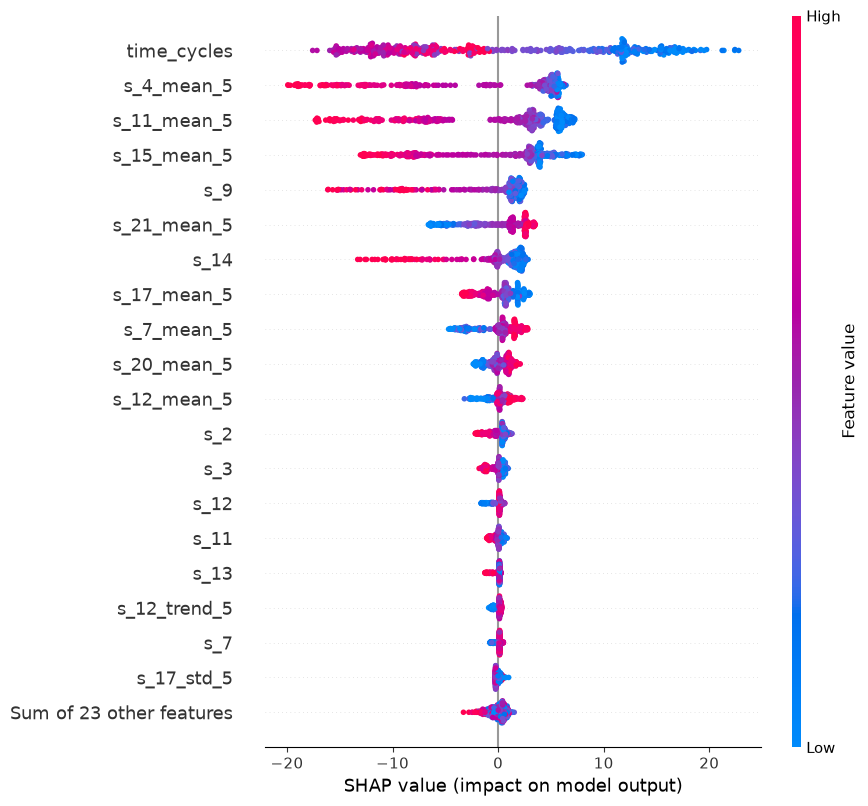

In [43]:
shap.plots.beeswarm(shap_values, max_display=20)

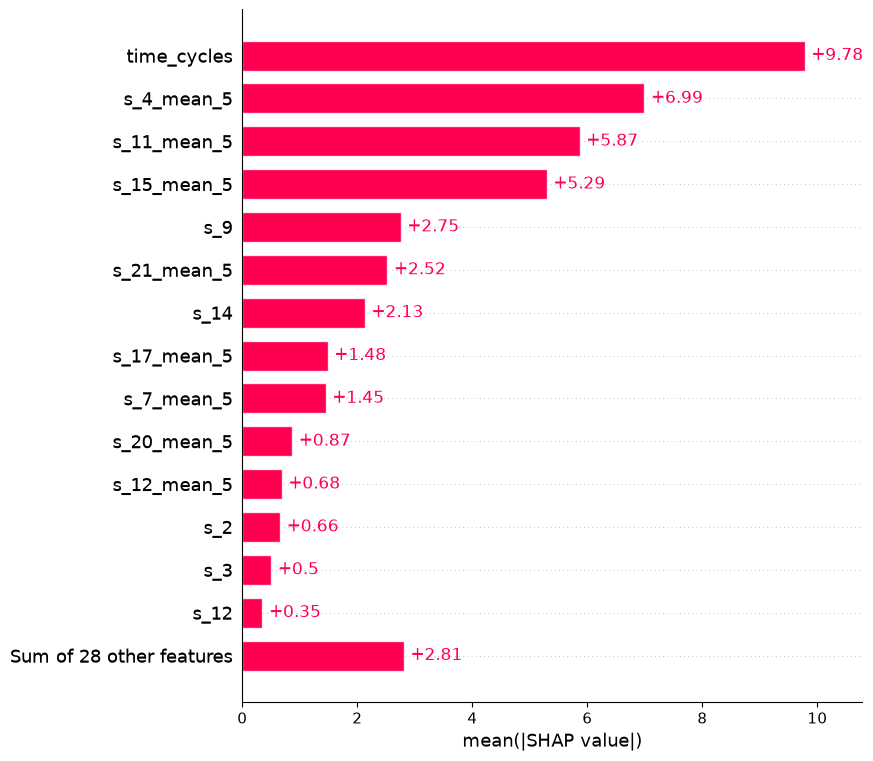

In [44]:
shap.plots.bar(shap_values, max_display=15)

In [45]:
import joblib
import os

In [46]:
os.makedirs('../artifacts', exist_ok=True)

joblib.dump(best_xgb, '../artifacts/best_model.pkl')

joblib.dump(
    list(X_train.columns),
    '../artifacts/feature_columns.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [47]:
# Calculate the final operating cycle for each test engine
test_max_cycles = test.groupby('unit_number')['time_cycles'].max()

# Generate rolling features using test engine histories
test_fe = create_features(test)

# Calculate actual RUL for each final test observation
test_final = test_fe.groupby('unit_number').tail(1).copy()

test_final['RUL'] = (
    test_final['unit_number']
    .map(test_max_cycles)
    .values
)

test_final['RUL'] = (
    test_final['RUL'].values * 0
    + y_test['RUL'].values
)

print("Final test observations:", test_final.shape)
print("Actual test RUL:", y_test.shape)

Final test observations: (100, 44)
Actual test RUL: (100, 1)


In [48]:
test_final['RUL'] = y_test['RUL'].values

In [49]:
import joblib

loaded_model = joblib.load('../artifacts/best_model.pkl')

feature_columns = joblib.load(
    '../artifacts/feature_columns.pkl'
)

print("Model loaded successfully!")

Model loaded successfully!


In [50]:
# Remove identifiers and target
X_test = test_final.drop(
    columns=['unit_number', 'RUL']
)

# Ensure exactly the same feature columns and order as training
X_test = X_test.reindex(columns=feature_columns)

print("Test feature shape:", X_test.shape)
print("Expected feature count:", len(feature_columns))

Test feature shape: (100, 42)
Expected feature count: 42


In [51]:
test_predictions = loaded_model.predict(X_test)

print("First 10 predictions:")
print(test_predictions[:10])

First 10 predictions:
[126.31865  119.67768   50.370094  78.28472   97.38219   90.65083
  99.37669   85.76735  116.827614 106.20153 ]


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = test_final['RUL'].values

test_mae = mean_absolute_error(
    actual, test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(actual, test_predictions)
)

print("Official Test MAE:", test_mae)
print("Official Test RMSE:", test_rmse)

Official Test MAE: 13.243408203125
Official Test RMSE: 17.943552305380823


In [53]:
comparison = pd.DataFrame({
    'Engine ID': test_final['unit_number'].values,
    'Actual RUL': actual,
    'Predicted RUL': np.round(test_predictions, 2)
})

comparison['Error'] = (
    comparison['Predicted RUL'] - comparison['Actual RUL']
)

display(comparison.head(15))

,Engine ID,Actual RUL,Predicted RUL,Error
0,1,112,126.320000,14.320000
1,2,98,119.680000,21.680000
2,3,69,50.369999,-18.630001
3,4,82,78.279999,-3.720001
4,5,91,97.379997,6.379997
5,6,93,90.650002,-2.349998
6,7,91,99.379997,8.379997
7,8,95,85.769997,-9.230003
8,9,111,116.830002,5.830002
9,10,96,106.199997,10.199997


In [54]:
def nasa_score(actual, predicted):

    errors = predicted - actual

    scores = np.where(
        errors < 0,
        np.exp(-errors / 13) - 1,
        np.exp(errors / 10) - 1
    )

    return np.sum(scores)


score = nasa_score(actual, test_predictions)

print("NASA Score:", score)

NASA Score: 538.5712790804732


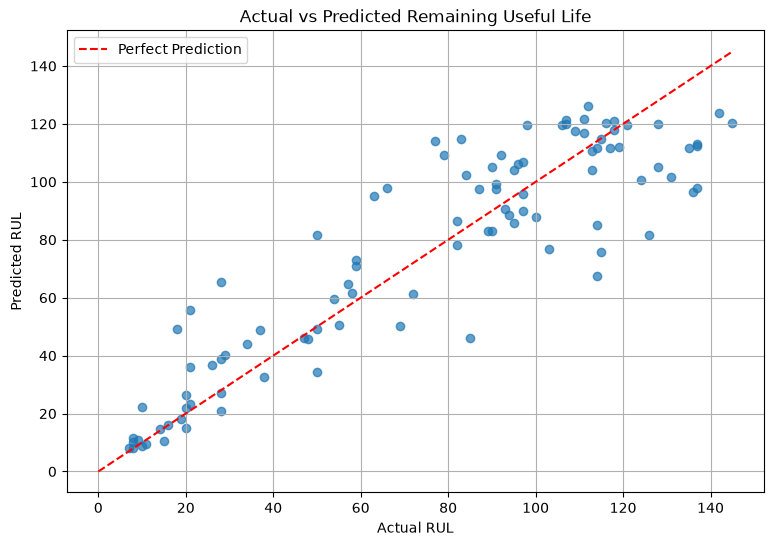

In [55]:
plt.figure(figsize=(9, 6))

plt.scatter(
    actual,
    test_predictions,
    alpha=0.7
)

plt.plot(
    [0, max(actual)],
    [0, max(actual)],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted Remaining Useful Life")

plt.legend()
plt.grid(True)
plt.show()

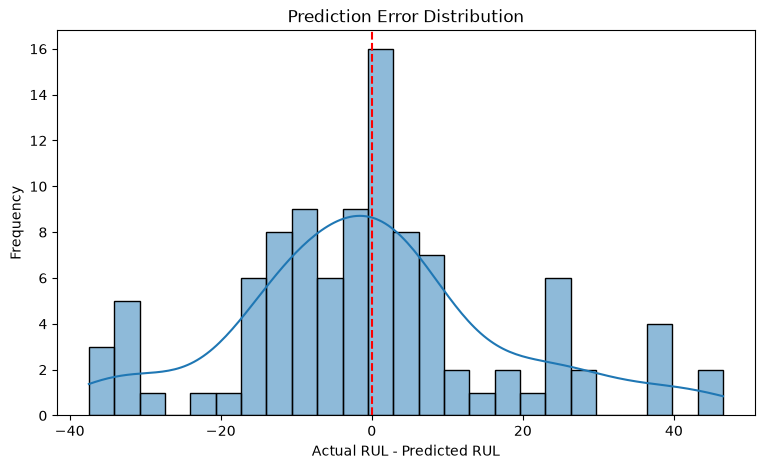

In [56]:
errors = actual - test_predictions

plt.figure(figsize=(9, 5))

sns.histplot(errors, bins=25, kde=True)

plt.axvline(0, color='red', linestyle='--')

plt.title("Prediction Error Distribution")
plt.xlabel("Actual RUL - Predicted RUL")
plt.ylabel("Frequency")

plt.show()

In [60]:
import json

payload = {
    "features": X_test.iloc[0].to_dict()
}

with open("../artifacts/sample_request.json", "w") as f:
    json.dump(payload, f, indent=4)

print("Complete JSON file created!")

Complete JSON file created!


In [66]:
import sys

!{sys.executable} -m pip install requests

'c:\Users\Niraj' is not recognized as an internal or external command,
operable program or batch file.


In [67]:
import requests

print("Requests installed successfully!")
print(requests.__version__)

ModuleNotFoundError: No module named 'requests'

In [68]:
import subprocess
import sys

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "requests"
])

0

In [69]:
import requests

print("Requests installed successfully!")
print(requests.__version__)

Requests installed successfully!
2.34.2


In [70]:
import requests

response = requests.post(
    "http://127.0.0.1:8000/predict",
    json=payload
)

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'predicted_rul': 126.32, 'unit': 'operating cycles'}


In [71]:
import json

demo_engines = {}

for _, row in test_final.iterrows():

    engine_id = int(row['unit_number'])

    features = row[feature_columns].to_dict()

    demo_engines[engine_id] = features

with open('../artifacts/demo_engines.json', 'w') as f:
    json.dump(demo_engines, f, indent=4)

print("Demo engine data saved!")
print("Total engines:", len(demo_engines))

Demo engine data saved!
Total engines: 100


In [73]:
import json
import re
import os

# Identify raw sensor columns
sensor_cols = [
    c for c in train.columns
    if re.fullmatch(r's_\d+', c)
]

# Export complete engine histories
history_data = {}

for engine_id, group in test_fe.groupby('unit_number'):

    group = group.sort_values('time_cycles')

    history_data[str(int(engine_id))] = (
        group[['time_cycles'] + sensor_cols]
        .to_dict(orient='records')
    )

# Save engine histories
with open('../artifacts/demo_engine_history.json', 'w') as f:
    json.dump(history_data, f, indent=2)

# Calculate empirical sensor reference ranges
sensor_ranges = {}

for sensor in sensor_cols:

    sensor_ranges[sensor] = {
        'p01': float(train[sensor].quantile(0.01)),
        'p99': float(train[sensor].quantile(0.99)),
        'median': float(train[sensor].median())
    }

with open('../artifacts/sensor_ranges.json', 'w') as f:
    json.dump(sensor_ranges, f, indent=4)

print("Engine histories exported:", len(history_data))
print("Sensor reference ranges exported:", len(sensor_ranges))

Engine histories exported: 100
Sensor reference ranges exported: 15
